# Which African Country Has the Most Languages?

This page uses the [TidyTuesday 2026-01-13 dataset](https://github.com/rfordatascience/tidytuesday/tree/main/data/2026/2026-01-13)
on popular languages of Africa, scraped from the Wikipedia page
*Languages of Africa*. Each row is one language–country pair, with the language's
family and its number of native speakers.

**Question:** which country in Africa has the largest number of spoken languages?

```{note} What this dataset counts
:class: dropdown
Africa has somewhere between 1,250 and 2,100+ native languages, but this dataset
only covers the **popular** languages listed in one Wikipedia table (about 500
languages). So "number of languages" here means *number of listed languages
linked to that country*, not every language spoken there.
```

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-01-13/africa.csv"
local = "data/africa.csv"
africa = pd.read_csv(local if os.path.exists(local) else url)

print(f"Rows: {len(africa):,}")
print(f"Exact duplicate rows: {africa.duplicated().sum()}")
print(f"Languages: {africa['language'].nunique()}")
print(f"Countries: {africa['country'].nunique()}")
africa.head()

Rows: 796
Exact duplicate rows: 34
Languages: 502
Countries: 51


,language,family,native_speakers,country
0,ǂKxʼaoǁʼae,Kxʼa,5000,Namibia
1,ǂKxʼaoǁʼae,Kxʼa,5000,Botswana
2,Abon,Niger–Congo,800,Cameroon
3,Abron,Niger–Congo,1393000,Ghana
4,Abron,Niger–Congo,1393000,Ivory Coast


## Counting languages per country

Some rows are exact duplicates, so we count **unique** languages per country
rather than rows.

In [2]:
langs_per_country = (
    africa.groupby("country")["language"]
    .nunique()
    .sort_values(ascending=False)
    .rename("n_languages")
)

top_country = langs_per_country.index[0]
print(f"Country with the most languages: {top_country} ({langs_per_country.iloc[0]} languages)")
print(f"Median across {len(langs_per_country)} countries: {langs_per_country.median():.0f} languages")
langs_per_country.head(10).to_frame()

Country with the most languages: Cameroon (95 languages)
Median across 51 countries: 9 languages


,n_languages
country,
Cameroon,95
Congo,79
Nigeria,73
Sudan,40
Burkina Faso,36
Ghana,34
Namibia,24
Chad,24
South Sudan,23


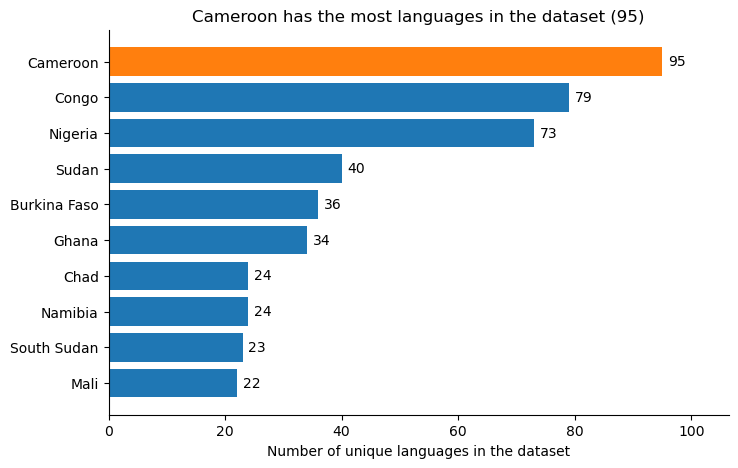

In [3]:
top10 = langs_per_country.head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:orange" if c == top_country else "tab:blue" for c in top10.index]
ax.barh(top10.index, top10.values, color=colors)
for y, v in enumerate(top10.values):
    ax.text(v + 1, y, str(v), va="center")
ax.set_xlabel("Number of unique languages in the dataset")
ax.set_title(f"{top_country} has the most languages in the dataset ({langs_per_country.max()})")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, top10.max() * 1.12)

os.makedirs("images", exist_ok=True)
fig.savefig("images/languages_per_country.png", dpi=150, bbox_inches="tight")
plt.show()

## Results

```{figure} images/languages_per_country.png
:name: fig-langs-per-country
:alt: Horizontal bar chart of the ten African countries with the most languages in the dataset, with Cameroon at the top
:width: 85%

The ten countries with the most unique languages in the dataset. Cameroon leads,
followed by "Congo" and Nigeria.
```

[Cameroon](#fig-langs-per-country) has the most languages in this dataset, ahead of
"Congo" and Nigeria. Most countries have far fewer: the median country has only
about 9 listed languages.

```{warning} Caveats
- **"Congo" is two countries.** The cleaning script matches country names with a
  regular expression, so the Democratic Republic of the Congo and the Republic of
  the Congo are merged into one "Congo" row. Its count is probably inflated.
- **Coverage is uneven.** The dataset lists popular languages only, so countries
  whose languages are better documented on Wikipedia may look more diverse.
- **Counts are not causes.** These are descriptive counts; they don't explain *why*
  some countries have more languages.
```